In [31]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
VAL_START = pd.Timestamp("2025-06-01")    # must match the split used in base_models_training
PRED_DIR = Path("base_preds")
BASE_MODELS = None                         # list of base model names, or None for every model in PRED_DIR
ALPHAS = np.logspace(-4, 3, 50)            # ridge penalties to search over
K_FOLDS = 5                                # time series cross validation folds for picking alpha

In [33]:
import data

listings = data.load("listings")
train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

names = BASE_MODELS or sorted(p.name.removesuffix("_train.parquet") for p in PRED_DIR.glob("*_train.parquet"))
print("base models:", names)

# One column of log price predictions per base model.
# Rows in the first fold block have no OOF prediction, so they are dropped.
X_train = pd.concat([pd.read_parquet(PRED_DIR / f"{n}_train.parquet") for n in names], axis=1).dropna()
X_val = pd.concat([pd.read_parquet(PRED_DIR / f"{n}_val.parquet") for n in names], axis=1)

y_train = np.log(train.loc[X_train.index, "sold_price"])
y_val = np.log(val.loc[X_val.index, "sold_price"])

print(f"meta train: {len(X_train):,} rows with OOF predictions")
print(f"meta val:   {len(X_val):,} rows")

base models: ['municipality', 'style', 'type']
meta train: 106,465 rows with OOF predictions
meta val:   22,238 rows


In [34]:
def mdape(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

In [35]:
# X_train is sorted by date_sold, so TimeSeriesSplit picks alpha with walk-forward folds.
meta = RidgeCV(alphas=ALPHAS, cv=TimeSeriesSplit(n_splits=K_FOLDS))
meta.fit(X_train, y_train)

print(f"alpha: {meta.alpha_:.4g}")
print(f"intercept: {meta.intercept_:.4f}")
display(pd.Series(meta.coef_, index=X_train.columns, name="weight").sort_values(ascending=False))

alpha: 0.0001
intercept: -0.0530


municipality    0.606289
type            0.310022
style           0.087267
Name: weight, dtype: float64

In [ ]:
from sklearn.linear_model import Ridge

# Walk-forward folds with the chosen alpha: each fold trains on every row before its validation block.
fold_scores = []
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=K_FOLDS).split(X_train), start=1):
    fold_model = Ridge(alpha=meta.alpha_).fit(X_train.iloc[tr], y_train.iloc[tr])
    pred = fold_model.predict(X_train.iloc[va])
    fold_scores.append({"fold": fold, "train": len(tr), "val": len(va),
                        "MdAPE": mdape(y_train.iloc[va], pred), "MAPE": mape(y_train.iloc[va], pred)})

fold_scores = pd.DataFrame(fold_scores).set_index("fold")
fold_scores.loc["mean"] = fold_scores.mean()
fold_scores.round(2)

,train,val,MdAPE,MAPE
fold,,,,
1,17745.0,17744.0,9.94,12.33
2,35489.0,17744.0,10.82,14.19
3,53233.0,17744.0,9.76,12.46
4,70977.0,17744.0,9.86,12.99
5,88721.0,17744.0,9.66,12.64
mean,53233.0,17744.0,10.01,12.92


In [37]:
pred_val = meta.predict(X_val)

candidates = {name: X_val[name] for name in X_val.columns}
candidates["simple average"] = X_val.mean(axis=1)
candidates["meta (ridge)"] = pred_val

scores = pd.DataFrame({
    "MdAPE": {k: mdape(y_val, p) for k, p in candidates.items()},
    "MAPE": {k: mape(y_val, p) for k, p in candidates.items()},
}).round(2).sort_values("MdAPE")
scores

,MdAPE,MAPE
meta (ridge),9.87,12.81
municipality,9.99,13.05
simple average,10.19,13.22
type,10.42,13.44
style,11.05,15.20


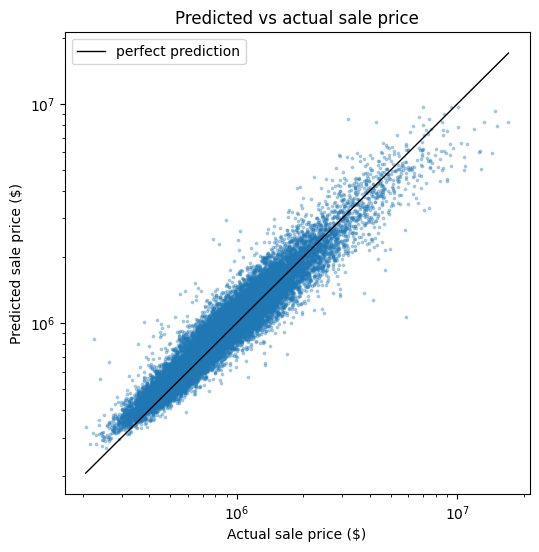

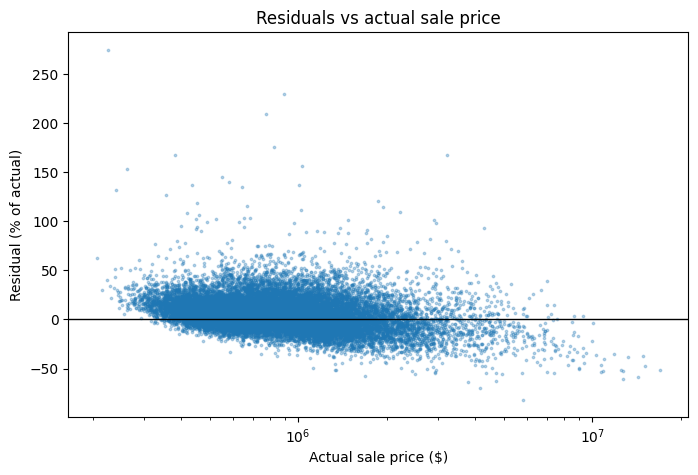

In [38]:
import diagnostics

actual = val.loc[X_val.index, "sold_price"]
predicted = np.exp(pred_val)

diagnostics.plot_predicted_vs_actual(actual, predicted)
diagnostics.plot_residuals_vs_actual(actual, predicted)